In [1]:
from utils import *
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
import pandas as pd

from sklearn.preprocessing import normalize

In [2]:
def gen_data(N=100, p=2, scale=1):

    #N = 10000
    #p = 10
    theta = scale*np.random.rand(p)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = np.random.rand(p*N).reshape(N, p)
    f = x @ theta
    p = expit(f)
    y = np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [3]:
ss = 10
algos_dict = {
    'Greedy_test_1': [Greedy_test_1, {'k':ss}, 10, 'Greedy_test_1', 'b'],
  'Greedy_logistic': [Greedy_logistic, {'k':ss}, 10, 'Greedy_logistic', 'g'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'y'],
    #'Greedy_logistic_Frechet': [Greedy_logistic_Frechet, {'k':ss, 'ss':6, 'dim':5}, 10, 'Greedy_logistic_Frechet', 'r'],
    'Greedy_logistic_Frechet_2': [Greedy_logistic_Frechet_2, {'k':ss, 'ss':4, 'dim':4, 'supp':(0,1)}, 10, 'Greedy_logistic_Frechet_2', 'm'],
    
}

In [5]:
ss = 10
algos_dict = {
    'TS_linear': [TS_linear, {}, 100, 'TS_linear', 'y'],  
    'Greedy_linear': [Greedy_linear, {}, 100, 'Greedy_linear', 'g'],  
    'Greedy_logistic_Frechet_2': [Greedy_logistic_Frechet_2, {'k':ss, 'ss':4, 'dim':3, 'supp':None}, 10, 'Greedy_Frechet', 'm'],
    'Greedy_logistic_Frechet_2': [Greedy_logistic_Frechet_2, {'k':ss, 'ss':4, 'dim':3, 'supp':None}, 10, 'Greedy_Frechet', 'm'],
    #'Greedy_Frechet': [Greedy_Frechet, {'k':ss, 'dim':4}, 100, 'Greedy_Frechet', 'b'], 
    #'Greedy_test_linear_kernel': [Greedy_test_linear_kernel, {'k':ss, 
    #                                                          'degree':5,
    #                                                          'kernel':'poly',
    #                                                          'sig_kernel':.1,
    #                                                          'kernel_dim':10}, 100, 'Greedy_test_linear_kernel', 'r'], 
    
}

In [6]:
M = 30
T = 100
reg_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
for trial_idx in trange(5):
    x, y, theta = gen_data(M, 2, 2)

    for algo, algo_setup in algos_dict.items():

        n_row, n_col = x.shape[0], 1
        _, n_desc =  x.shape
        cutoff = n_desc
        prob_dict = {
                    "m": n_row,
                    "noise": 0.01,
                    "d": cutoff,
                    "theta": theta,
                    }
        prob = mixture_discover(**prob_dict)
        prob.x = x.copy()
            
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup

        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd = solver.run(T)[:2]

        reg_list[algo].append(reg)
        rwd_list[algo].append(np.cumsum(rwd))


100%|█████████████████████████████████████████████| 5/5 [00:23<00:00,  4.79s/it]


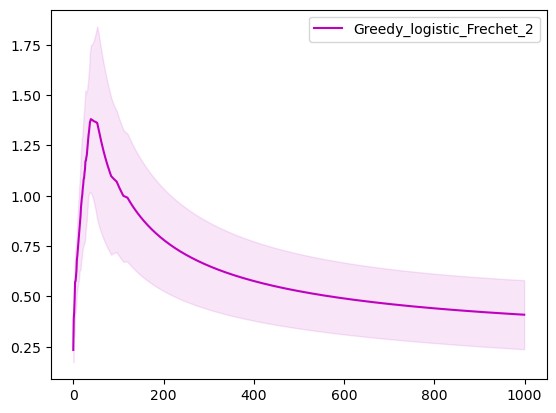

In [6]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

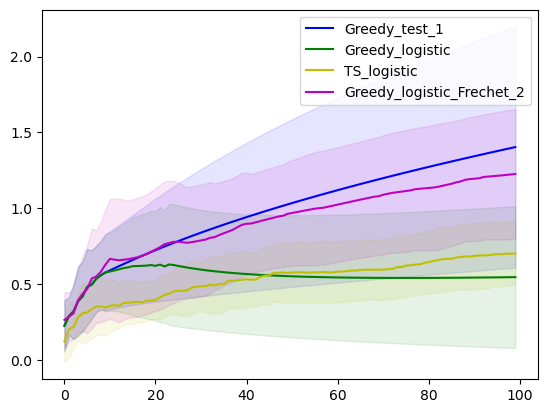

In [78]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

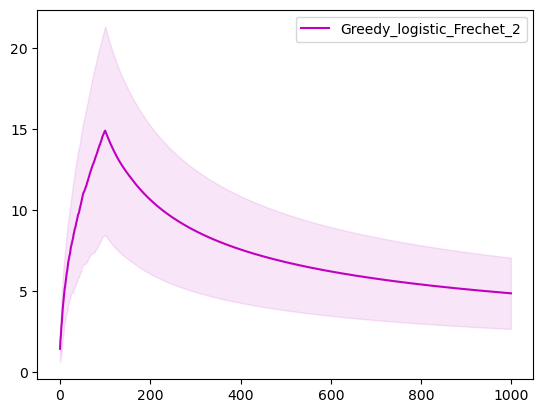

In [56]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

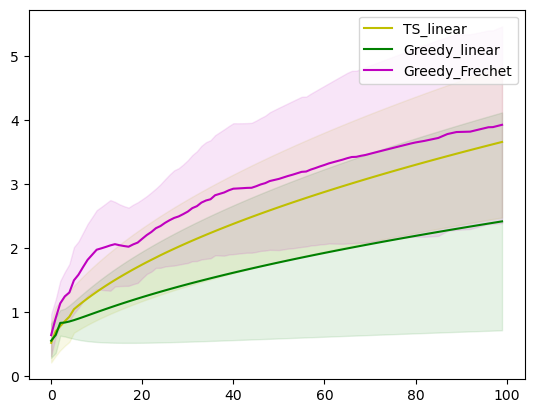

In [7]:
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:2000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:2000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [57]:
solver.S_k

array([ 27.,  37.,  37.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,  29.,
         0.,   0.,   0.,   0.,   0.,   0.,   0., 870.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.])

In [64]:
solver.prob.x @ solver.prob.theta

array([-0.00767455, -0.14512326, -0.02183136,  0.35423535, -0.36945472,
        0.03953526,  0.20489306,  0.40579766,  0.64626068,  0.22621066,
        0.92281079, -0.04934741,  0.52458301,  0.47452435, -0.44538869,
       -0.04528745,  0.6974729 ,  0.02210562,  0.95351484, -0.05334878,
       -0.58826606, -0.64687279,  0.0451126 ,  0.61213218, -0.12733244,
       -0.45749248, -0.33603134, -0.16624796,  0.52226144, -0.7492739 ])

In [59]:
solver.prob.actions

[1,
 2,
 1,
 0,
 2,
 0,
 1,
 2,
 2,
 2,
 0,
 1,
 0,
 2,
 1,
 0,
 2,
 2,
 2,
 2,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 2,
 1,
 1,
 2,
 2,
 0,
 1,
 0,
 0,
 0,
 1,
 2,
 0,
 2,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 1,
 1,
 1,
 1,
 2,
 2,
 1,
 2,
 0,
 1,
 2,
 1,
 2,
 0,
 2,
 1,
 0,
 0,
 0,
 1,
 0,
 2,
 1,
 0,
 2,
 0,
 1,
 2,
 0,
 2,
 0,
 2,
 2,
 2,
 2,
 1,
 2,
 1,
 1,
 2,
 2,
 1,
 2,
 1,
 0,
 0,
 0,
 0,
 2,
 2,
 2,
 0,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 10,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 18,
 

In [141]:
top_arms = np.argsort(solver.S_k)[::-1][:solver.dim]
u = np.linspace(1e-7, 1-1e-7, 1000)
        
quantiles = [
            (pd.DataFrame({'action':solver.prob.actions, 'reward':np.array(solver.prob.rewards).flatten()}).
             groupby('action').
             quantile(u).
             reset_index().query('action == @i').iloc[:,2].to_numpy()) for i in top_arms
            ]

In [66]:
top_arms

array([18,  1,  2])

In [13]:
np.sum(np.diff(quantiles[0],1) * (1-u)[1:])

0.03296799018913396

In [14]:
df = pd.DataFrame({'q':quantiles[0], 'p':u}).groupby('q').count().reset_index()
(df['p'] * df['q']).sum() / (u.shape[0])

1.2151612451149336

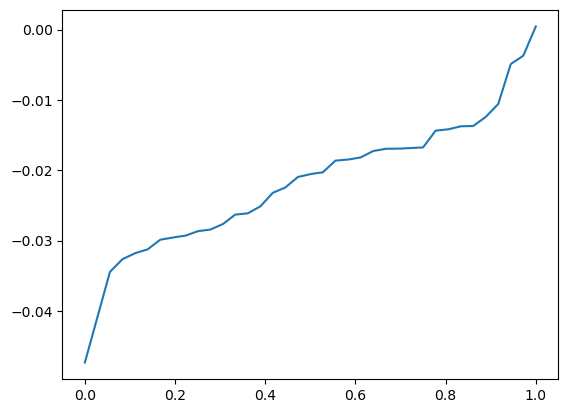

In [69]:
plt.plot(u, quantiles[2])

In [20]:
class distr_reg_2:
    def __init__(self):
        self.a = ''
        
    def s_in(self, x, i, X, X_bar, sigma_X_inv):
        s = 1 + (X[i] - X_bar) @ sigma_X_inv @ (x - X_bar)     
        
        return s
        
    def predict(self, x_new, x, y, M=100):
        
        N = x.shape[0]
        x_bar = x.mean(0)
        sigma_x = np.cov(x.T)
        sigma_x_inv = np.linalg.inv(sigma_x)
        #s_in_x = s_in(x, i, X, X_bar, sigma_X_inv)
        #u = np.linspace(1e-7, 1-1e-7, M)
        
        
        g = 0
        s = []
        for i in range(N):
            s.append(self.s_in(x_new, i, x, x_bar, sigma_x_inv))
            g = g + self.s_in(x_new, i, x, x_bar, sigma_x_inv)*y[i]
                
        g = g / N
        
        return g, s

In [45]:
x = solver.prob.x
dr = distr_reg_2()
mus1 = []
mus2 = []
for i in range(solver.prob.m):
            #g, _ = dr.predict(x_new=x[i], x=x[top_arms], y=dist,M=1000)
    g, _ = dr.predict(x_new=x[i], x=x[top_arms], y=quantiles,M=1000)
            
    iso_reg = IsotonicRegression(y_min=0, y_max=1).fit(u, g)
            #mu_i = np.sum(np.diff(iso_reg.predict(u),1) * (1-u)[1:])
            #mu_i = iso_reg.predict(u)[500]
    df = pd.DataFrame({'q':iso_reg.predict(u), 'p':u}).groupby('q').count().reset_index()
            #mu_i = (df['p'] * df['q']).sum() / u.shape[0]
    mu_i1 = np.sum(np.diff(iso_reg.predict(u),1) * (1-u)[1:])
    mu_i2 = (df['p'] * df['q']).sum() / u.shape[0]

    mus1.append(mu_i1)
    mus2.append(mu_i2)

In [46]:
iso_reg.predict(u)

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

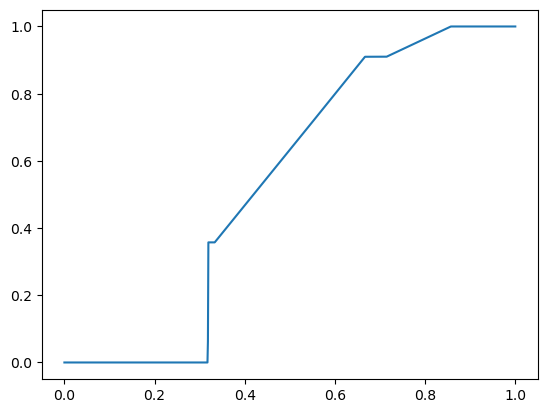

In [47]:
plt.plot(u, iso_reg.predict(u))

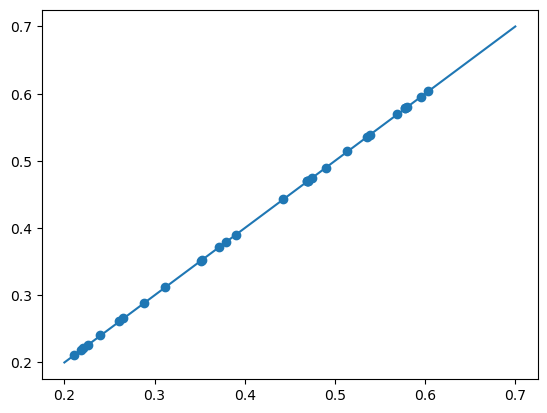

In [48]:
plt.scatter(mus1, mus2)
plt.plot(np.linspace(.2,.7,100), np.linspace(.2,.7,100))

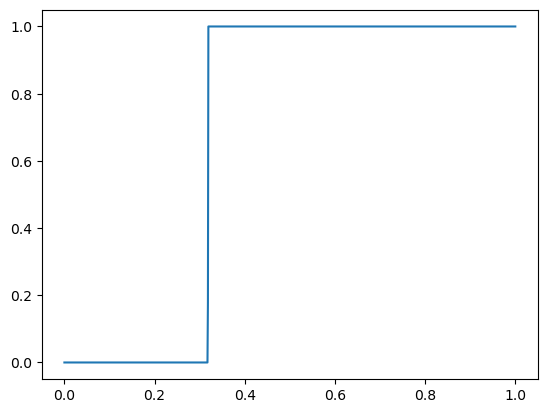

In [12]:
plt.plot(u, quantiles[0])

In [15]:
from scipy.stats import norm, bernoulli, binom 

In [154]:
rv = norm(-1)
q = rv.ppf(u)
#Dt = np.diff(u,1) / (np.diff(rv.ppf(u),1))
#t = (rv.ppf(u)[1:] + rv.ppf(u)[:-1]) / 2
#dt = np.diff(t, 1)
#dt = (dt[1:] + dt[:-1]) / 2
#t = t[1:-1]
#Dt = Dt[1:-1]
#t = rv.ppf(u)[1:]
#t = rv.ppf(u)[:-1]

In [155]:
df = pd.DataFrame({'q':q, 'p':u}).groupby('q').count().reset_index()
(df['p'] * df['q']).sum() / 1000

-0.9999999999999021

In [14]:
np.sum(np.diff(quantiles[0],1) * (1-u)[1:])

0.877905001517705

In [50]:
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
kernel = RBF(1)

In [45]:
x_ = np.random.normal(size=2)

In [48]:
x_ @ (np.linalg.inv(x.T @ x + np.eye(2)) @ x.T)

array([ 0.01290913, -0.00067712, -0.07377929,  0.08324217, -0.00640682,
       -0.03552006,  0.06056825, -0.01126457,  0.0034315 , -0.03963079,
       -0.04632159, -0.0459201 ,  0.04400034,  0.01655048,  0.01925863,
       -0.07519887,  0.05850738, -0.11456485, -0.04226358,  0.00770862,
        0.01165172,  0.00833356, -0.06724151,  0.04493712,  0.0943592 ,
        0.04467355, -0.02085099, -0.0005336 , -0.11016783, -0.00908111])

In [49]:
(x_ @ (x.T)) @ np.linalg.inv(x @ x.T + np.eye(30))

array([ 0.01290913, -0.00067712, -0.07377929,  0.08324217, -0.00640682,
       -0.03552006,  0.06056825, -0.01126457,  0.0034315 , -0.03963079,
       -0.04632159, -0.0459201 ,  0.04400034,  0.01655048,  0.01925863,
       -0.07519887,  0.05850738, -0.11456485, -0.04226358,  0.00770862,
        0.01165172,  0.00833356, -0.06724151,  0.04493712,  0.0943592 ,
        0.04467355, -0.02085099, -0.0005336 , -0.11016783, -0.00908111])

In [66]:
x[0,:]

array([0.07192059, 0.84772388])

In [72]:
kernel(x_, x[0:1,:])

array([[0.61623476]])

In [78]:
(kernel(x_, x) @ np.linalg.inv(kernel(x) + np.eye(30)))[0,0]

0.01188672236296591

In [280]:
class distr_reg:
    def __init__(self):
        self.a = ''
        
    def s_in(self, x, i, X, X_bar, sigma_X_inv):
        s = 1 + (X[i] - X_bar) @ sigma_X_inv @ (x - X_bar)     
        
        return s
        
    def predict(self, x_new, x, y, M=100):
        
        N = x.shape[0]
        x_bar = x.mean(0)
        sigma_x = np.cov(x.T)
        sigma_x_inv = np.linalg.inv(sigma_x)
        #s_in_x = s_in(x, i, X, X_bar, sigma_X_inv)
        u = np.linspace(1e-7, 1-1e-7, M)
        
        
        g = 0
        s = []
        for i in range(N):
            s.append(self.s_in(x_new, i, x, x_bar, sigma_x_inv))
            g = g + self.s_in(x_new, i, x, x_bar, sigma_x_inv)*y[i].ppf(u)
                
        g = g / N
        
        return g, s
    
    
class distr_reg_2:
    def __init__(self):
        self.a = ''
        
    def s_in(self, x, i, X, X_bar, sigma_X_inv):
        s = 1 + (X[i] - X_bar) @ sigma_X_inv @ (x - X_bar)     
        
        return s
        
    def predict(self, x_new, x, y, M=100):
        
        N = x.shape[0]
        x_bar = x.mean(0)
        sigma_x = np.cov(x.T)
        sigma_x_inv = np.linalg.inv(sigma_x)
        #s_in_x = s_in(x, i, X, X_bar, sigma_X_inv)
        #u = np.linspace(1e-7, 1-1e-7, M)
        
        
        g = 0
        s = []
        for i in range(N):
            s.append(self.s_in(x_new, i, x, x_bar, sigma_x_inv))
            g = g + self.s_in(x_new, i, x, x_bar, sigma_x_inv)*y[i]
                
        g = g / N
        
        return g, s
    
class distr_reg_3:
    def __init__(self):
        self.a = ''
        
    def init_kernel(self, ):
        self.kernel = RBF(10)
        
    def s_in(self, x, i, X, X_bar, sigma_X_inv):
        
        #s = 1 + (X[i] - X_bar) @ sigma_X_inv @ (x - X_bar)     
        s = 1 + (self.kernel(x, X) @ np.linalg.inv(self.kernel(X) + 10*np.eye(X.shape[0])))[0, i]
        
        return s
        
    def predict(self, x_new, x, y, M=100):
        
        N = x.shape[0]
        x_bar = x.mean(0)
        sigma_x = np.cov(x.T)
        sigma_x_inv = np.linalg.inv(sigma_x)
        #s_in_x = s_in(x, i, X, X_bar, sigma_X_inv)
        #u = np.linspace(1e-7, 1-1e-7, M)
        
        
        g = 0
        s = []
        for i in range(N):
            s.append(self.s_in(x_new, i, x, x_bar, sigma_x_inv))
            g = g + self.s_in(x_new, i, x, x_bar, sigma_x_inv)*y[i]
                
        g = g / N
        
        return g, s

In [249]:
from scipy.stats import norm, bernoulli, binom, gamma, poisson

In [281]:
distr = [poisson(t) for t in np.exp(x @ theta)]
sim = [rv.rvs(30)  for rv in distr ]
quant = [np.quantile(s, u) for s in sim]
quant_t = [rv.ppf(u) for rv in distr]

In [282]:
dr1 = distr_reg()
dr2 = distr_reg_2()
dr3 = distr_reg_3()
dr3.init_kernel()
g1, _ = dr1.predict(x_new=x[10], x=x[:5], y=distr[:5],M=1000)
g2, _ = dr2.predict(x_new=x[10], x=x[:5], y=quant[:5],M=1000)
g3, _ = dr3.predict(x_new=x[10], x=x[:5], y=quant[:5],M=1000)

iso_reg1 = IsotonicRegression(y_min=0, y_max=None).fit(u, g1)
iso_reg2 = IsotonicRegression(y_min=0, y_max=None).fit(u, g2)
iso_reg3 = IsotonicRegression(y_min=0, y_max=None).fit(u, g3)

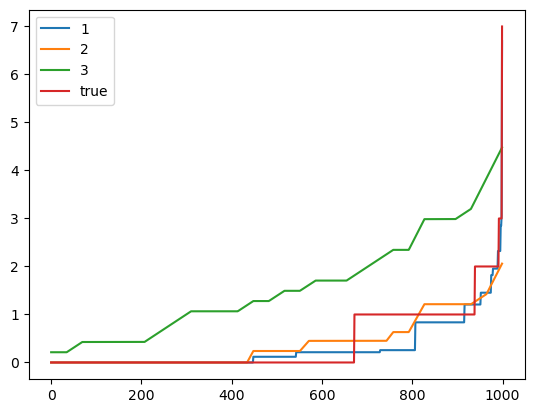

In [283]:
plt.plot(iso_reg1.predict(u), label='1')
plt.plot(iso_reg2.predict(u), label='2')
plt.plot(iso_reg3.predict(u), label='3')
plt.plot(quant_t[10], label='true')
plt.legend()

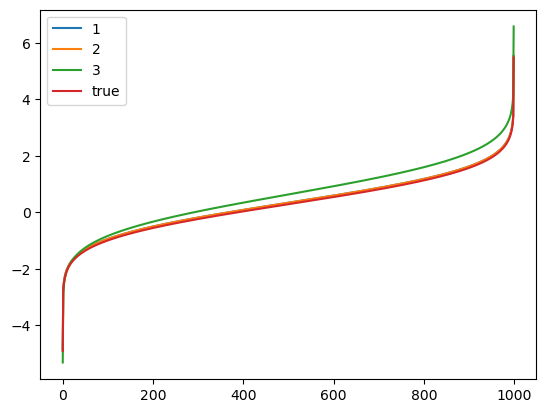

In [176]:
plt.plot(g1, label='1')
plt.plot(g2, label='2')
plt.plot(g3, label='3')
plt.plot(quant[10], label='true')
plt.legend()

In [129]:
x = solver.prob.x
dr = distr_reg_3()
gs = []
for i in range(solver.prob.m):
            #g, _ = dr.predict(x_new=x[i], x=x[top_arms], y=dist,M=1000)
    dr.init_kernel()
    g, _ = dr.predict(x_new=x[i], x=x[top_arms], y=quantiles,M=1000)
    gs.append(g)

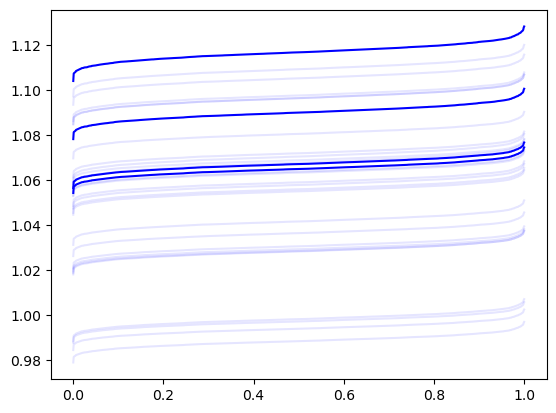

In [135]:
for i in range(30):
    if i in top_arms:
        plt.plot(u, gs[i], c='b')
        j = np.where(top_arms == i)[0][0]
        #plt.plot(u, quantiles[j], c='r')
    else:
        plt.plot(u, gs[i], c='b', alpha=.1)



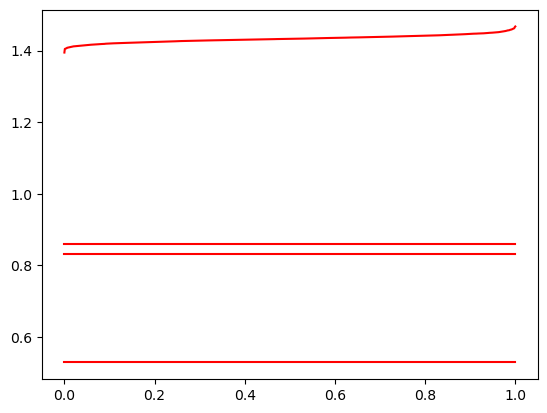

In [133]:
for q in quantiles:
    plt.plot(u, q, c='r')

In [77]:
gpr = GaussianProcessRegressor(kernel=kernel, random_state=0)

In [79]:
from scipy.stats import multivariate_normal

In [107]:
rv1 = multivariate_normal([.5,.5], .1)
rv2 = multivariate_normal([-.5,-.5], .1)
rv3 = multivariate_normal([.5,-.5], .1)
rv4 = multivariate_normal([-.5,.5], .1)

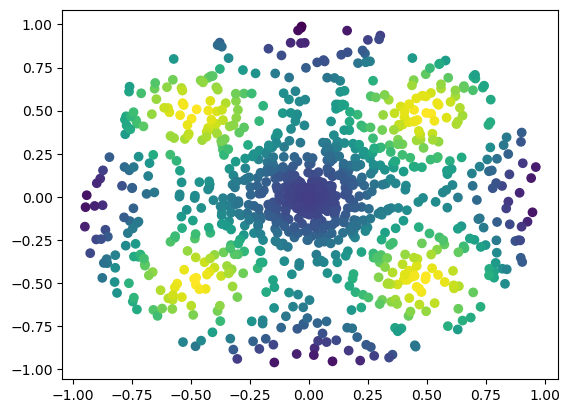

In [108]:
x, y, theta = gen_data(1000, 2, 2)
x = x
plt.scatter(x[:,0],x[:,1],c=(rv1.pdf(x)+
rv2.pdf(x)+
rv3.pdf(x)+
rv4.pdf(x)))